# Chapter 2 · Closing the gap in 1D: calibration and the Kalman filter
1D

Chapter 1 ended with an open-loop twin that drifted because it had the **wrong parameters** and
the **wrong input**. This chapter fixes both, in two parts:

| Part | Method | When it runs | What it fixes |
|---|---|---|---|
| **A. Calibration** | nonlinear least squares | once, offline, on recorded data | constant parameters such as $\alpha$ |
| **B. Kalman filter** | sequential Bayesian update | continuously, every time data arrive | the state and inputs that change over time |

Builds on Chapter 1 (the heat equation, `Heat1D`, $H$ and $R$). Some linear algebra
helps (matrix products, inverse), and so does knowing what a Gaussian distribution is.


---
# Part A · Calibration: learning parameters from data

## A0. The idea: why least squares?
The **forward problem** is easy: pick parameters $\theta$, run the simulator, read off the
predicted sensor values $H u_k(\theta)$. The **inverse problem** goes backwards: given the
measured $y_{k}$, which $\theta$ produced them?

Our noise model from Chapter 1 says each reading is the truth plus Gaussian noise of size $\sigma$.
So the probability (*likelihood*) of seeing the data if $\theta$ were true is

$$p(y\mid\theta) \propto \prod_{k,j}\exp\!\Big(-\frac{(y_{k,j} - [Hu_k(\theta)]_j)^2}{2\sigma^2}\Big).$$

Take $-\log$: maximising the likelihood is the same as **minimising the sum of squared residuals**

$$\boxed{\;J(\theta) = \frac{1}{2}\sum_{k,j} r_{k,j}(\theta)^2,\qquad r_{k,j} = \frac{y_{k,j} - [Hu_k(\theta)]_j}{\sigma}\;}$$

Dividing by $\sigma$ makes each residual unitless. "Residual = 1" means "off by one noise
standard deviation". At the true $\theta$, a good fit has $J \approx \tfrac12 \times$ (number of
readings).

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
from scipy.optimize import least_squares, minimize_scalar
from scipy.ndimage import gaussian_filter1d
from scipy.stats import chi2
from IPython.display import HTML
from dtwin import viz
from dtwin.solvers import Heat1D
from dtwin.sensors import PointSensors, evenly_spaced_1d
from dtwin.assimilation import KalmanFilter
viz.set_style()
rng = np.random.default_rng(3)

## A1. Setup: two unknowns
Reality: diffusivity $\alpha^\star=0.012$ and heater power $P^\star = 0.7$ (constant this time).
The twin knows the heater's location and shape but not $\alpha$ or $P$.

In [2]:
NX, DT, NSTEP = 61, 0.05, 200
ALPHA_TRUE, P_TRUE, SIGMA = 0.012, 0.7, 0.01
shape = lambda x: np.exp(-((x - 0.35) / 0.06) ** 2)

def forward(alpha, P, nx=NX):
    m = Heat1D(nx=nx, alpha=alpha, dt=DT)
    return m.x, m.simulate(np.zeros(nx), NSTEP, source=lambda x, t: P * shape(x))

x, (t, U_true) = forward(ALPHA_TRUE, P_TRUE)
sens = PointSensors(evenly_spaced_1d(NX, 6), NX, SIGMA)
Y = sens.observe(U_true, rng)

def residuals(theta, Y=Y, sens=sens):
    alpha, P = theta
    _, (_, U) = forward(alpha, P)
    return ((sens.observe(U) - Y) / SIGMA).ravel()

## A2. One parameter: the loss curve
Fix $P$ at its true value and scan $\alpha$. The cost $J(\alpha)$ has a clean minimum, and
`minimize_scalar` finds it in a few evaluations.

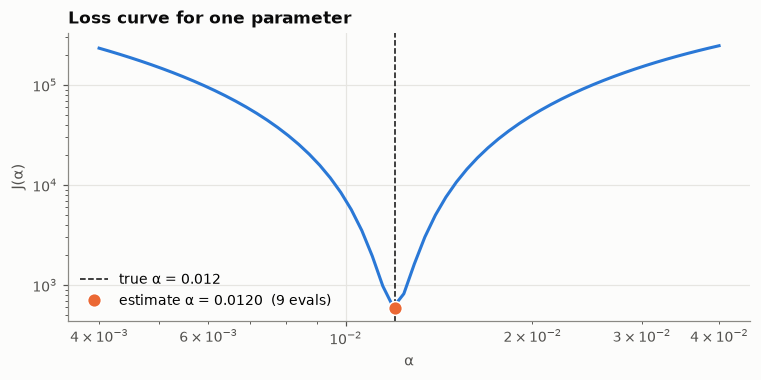

In [3]:
alphas = np.geomspace(0.004, 0.04, 60)
J1 = [0.5 * np.sum(residuals((a, P_TRUE)) ** 2) for a in alphas]
res1 = minimize_scalar(lambda la: 0.5 * np.sum(residuals((np.exp(la), P_TRUE)) ** 2),
                       bounds=np.log([0.004, 0.04]), method="bounded")
a_hat = np.exp(res1.x)

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.loglog(alphas, J1, color=viz.TWIN)
ax.axvline(ALPHA_TRUE, color=viz.TRUTH, ls="--", lw=1, label=f"true α = {ALPHA_TRUE}")
ax.plot(a_hat, res1.fun, "o", color=viz.DATA, ms=9, mec="white", label=f"estimate α = {a_hat:.4f}  ({res1.nfev} evals)")
ax.set(xlabel="α", ylabel="J(α)", title="Loss curve for one parameter")
ax.legend()
plt.show()

## A3. Inside the optimiser: Gauss-Newton by hand
What is `minimize_scalar` (or `least_squares`) actually doing? The workhorse for least squares is
**Gauss-Newton**. Here is the whole idea in three lines:

1. **Linearise** the residuals around the current guess: $r(\theta + \delta) \approx r(\theta) + J\,\delta$,
   where the Jacobian $J_{i} = \partial r_i/\partial\theta$.
2. The linearised cost $\tfrac12\|r + J\delta\|^2$ is a parabola in $\delta$. Its minimum solves
   the **normal equations** $\;(J^\top J)\,\delta = -J^\top r$.
3. Take the step $\theta \leftarrow \theta + \delta$ and repeat.

We code it for the single parameter $\alpha$, with the Jacobian from a finite difference
(rerun the model with $\alpha$ nudged slightly):

In [4]:
def gauss_newton_alpha(alpha0, n_iter=6, eps=1e-6):
    a, hist = alpha0, [alpha0]
    for it in range(n_iter):
        r = residuals((a, P_TRUE))
        Jac = (residuals((a + eps, P_TRUE)) - r) / eps     # d r / d alpha, one column
        delta = -(Jac @ r) / (Jac @ Jac)                   # normal equations, 1x1
        a = a + delta
        hist.append(a)
        print(f"iter {it+1}:  alpha = {a:.6f}   J = {0.5*np.sum(residuals((a, P_TRUE))**2):10.1f}")
    return np.array(hist)

gn_hist = gauss_newton_alpha(0.006)
print(f"true alpha = {ALPHA_TRUE};   number of readings / 2 = {Y[1:].size/2:.0f}")

iter 1:  alpha = 0.010045   J =     6739.9
iter 2:  alpha = 0.011818   J =      639.5
iter 3:  alpha = 0.011991   J =      597.8
iter 4:  alpha = 0.011992   J =      597.8
iter 5:  alpha = 0.011992   J =      597.8
iter 6:  alpha = 0.011992   J =      597.8
true alpha = 0.012;   number of readings / 2 = 600


From a guess that is 50% off, Gauss-Newton is within 1% after two or three
iterations. The final $J$ is close to (number of readings)/2: the leftover misfit is just noise,
so the fit has used all the information in the data and isn't **overfitting**.

Also note that $J^\top J$ appears in the step. It will return in A5 as the key to the error bars.

## A4. Two parameters: the loss landscape
Now both $\alpha$ and $P$ are unknown. The landscape is a **long, tilted valley**: a stronger
heater with faster diffusion produces almost the same sensor readings as a weaker heater with
slower diffusion. The parameters are **correlated**: the data constrain a *combination* of them
far better than each one separately.

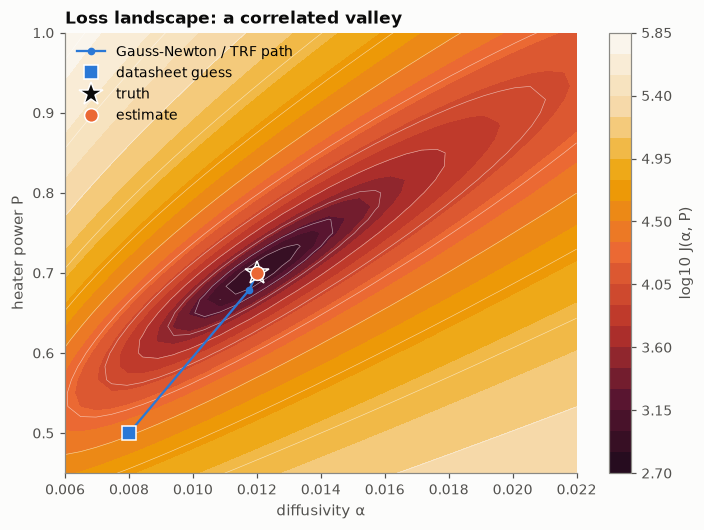

estimate: alpha = 0.01201 (true 0.012),  P = 0.7004 (true 0.7)


In [5]:
A_grid = np.linspace(0.006, 0.022, 34)
P_grid = np.linspace(0.45, 1.0, 34)
J2 = np.array([[0.5 * np.sum(residuals((a, p)) ** 2) for a in A_grid] for p in P_grid])

theta0 = np.array([0.008, 0.5])  # datasheet guess
path = [theta0]
fit = least_squares(residuals, theta0, x_scale=[0.01, 0.5], diff_step=1e-4)
# re-run step by step for the optimisation path (max_nfev grows each time)
for n in range(1, 12):
    r = least_squares(residuals, theta0, x_scale=[0.01, 0.5], diff_step=1e-4, max_nfev=n)
    path.append(r.x)
path = np.array(path)

fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.grid(False)
cs = ax.contourf(A_grid, P_grid, np.log10(J2), levels=25, cmap=viz.FIELD.reversed())
ax.contour(A_grid, P_grid, np.log10(J2), levels=12, colors="white", linewidths=0.4, alpha=0.6)
plt.colorbar(cs, label="log10 J(α, P)")
ax.plot(path[:, 0], path[:, 1], "-o", color=viz.TWIN, ms=4, lw=1.5, label="Gauss-Newton / TRF path")
ax.plot(*theta0, "s", color=viz.TWIN, ms=9, mec="white", label="datasheet guess")
ax.plot(ALPHA_TRUE, P_TRUE, "*", color=viz.INK, ms=16, mec="white", label="truth")
ax.plot(*fit.x, "o", color=viz.DATA, ms=9, mec="white", label="estimate")
ax.set(xlabel="diffusivity α", ylabel="heater power P", title="Loss landscape: a correlated valley")
ax.legend(loc="upper left")
viz.save(fig, "03_landscape.png")
plt.show()
print(f"estimate: alpha = {fit.x[0]:.5f} (true {ALPHA_TRUE}),  P = {fit.x[1]:.4f} (true {P_TRUE})")

## A5. How sure are we? Two ways to get error bars
**Gauss-Newton (Laplace) approximation:** near the optimum the cost is quadratic, so
$\operatorname{Cov}(\hat\theta) \approx (J^\top J)^{-1}$ where $J$ is the Jacobian of the
(σ-scaled) residuals. One calibration gives the full covariance at no extra cost.

**Monte Carlo:** repeat the experiment with fresh noise many times and look at the spread of
estimates. Expensive, but assumption-free. They should agree.

alpha = 0.01201 ± 0.00005   P = 0.7004 ± 0.0013   corr = +0.909


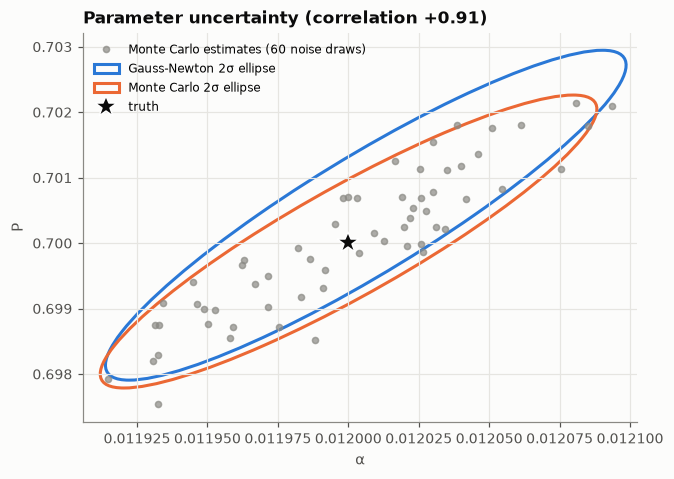

In [6]:
def gn_cov(fit):
    Jac = fit.jac
    return np.linalg.inv(Jac.T @ Jac)

def ellipse(ax, mean, cov, color, label, nsig=2):
    vals, vecs = np.linalg.eigh(cov)
    ang = np.degrees(np.arctan2(vecs[1, 1], vecs[0, 1]))
    w, h = 2 * nsig * np.sqrt(vals[::-1])
    ax.add_patch(Ellipse(mean, w, h, angle=ang, fill=False, color=color, lw=2, label=label))

C = gn_cov(fit)
sd = np.sqrt(np.diag(C))
corr = C[0, 1] / (sd[0] * sd[1])
print(f"alpha = {fit.x[0]:.5f} ± {sd[0]:.5f}   P = {fit.x[1]:.4f} ± {sd[1]:.4f}   corr = {corr:+.3f}")

mc = []
for _ in range(60):
    Yb = sens.observe(U_true, rng)
    mc.append(least_squares(lambda th: residuals(th, Yb), fit.x, x_scale=[0.01, 0.5], diff_step=1e-4).x)
mc = np.array(mc)

fig, ax = plt.subplots(figsize=(6.5, 4.6))
ax.plot(mc[:, 0], mc[:, 1], "o", color=viz.MUTED, ms=4, alpha=0.7, label="Monte Carlo estimates (60 noise draws)")
ellipse(ax, fit.x, C, viz.TWIN, "Gauss-Newton 2σ ellipse")
ellipse(ax, mc.mean(0), np.cov(mc.T), viz.DATA, "Monte Carlo 2σ ellipse")
ax.plot(ALPHA_TRUE, P_TRUE, "*", color=viz.INK, ms=15, mec="white", label="truth")
ax.set(xlabel="α", ylabel="P", title=f"Parameter uncertainty (correlation {corr:+.2f})")
ax.legend(fontsize=8)
plt.show()

## A6. Sensor placement decides what is identifiable
Same experiment, three sensor layouts. The ellipse area is the volume of uncertainty: smaller is
better, and its orientation shows *which combination* of parameters the layout cannot pin down.
* **far side**: these sensors only see a diffused, delayed signal, so $\alpha$ is poorly determined
* **2 sensors near the heater**: a long thin ellipse, meaning $\alpha$ and $P$ trade off almost perfectly
* **spread**: sees both the peak and the tails, giving the smallest ellipse

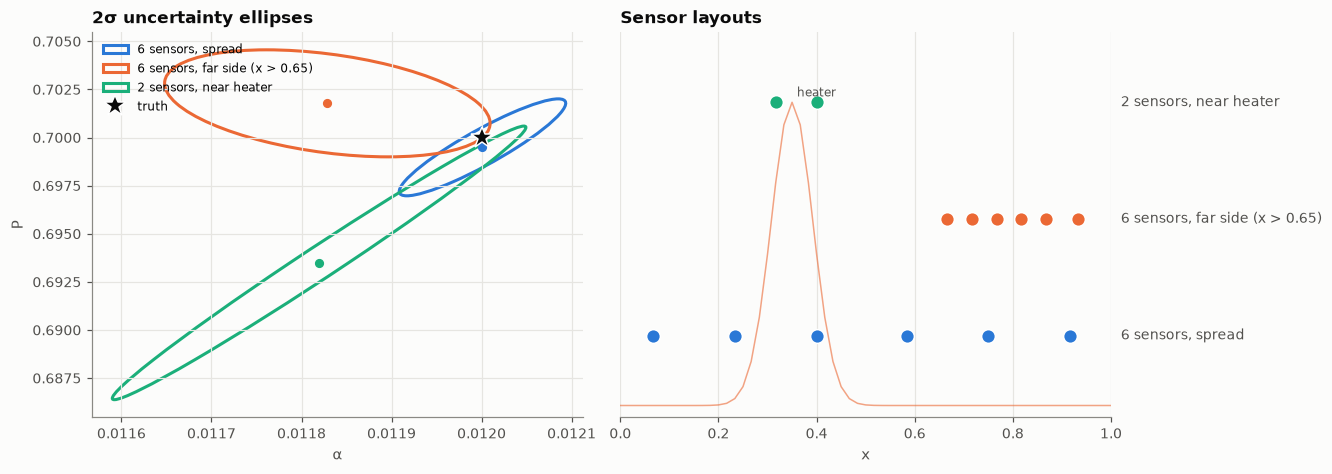

In [7]:
layouts = {
    "6 sensors, spread": evenly_spaced_1d(NX, 6),
    "6 sensors, far side (x > 0.65)": np.linspace(40, 56, 6).astype(int),
    "2 sensors, near heater": np.array([19, 24]),
}
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), constrained_layout=True)
for i, (name, idx) in enumerate(layouts.items()):
    s = PointSensors(idx, NX, SIGMA)
    Ys = s.observe(U_true, rng)
    f = least_squares(lambda th: residuals(th, Ys, s), [0.01, 0.6], x_scale=[0.01, 0.5], diff_step=1e-4)
    Ci = gn_cov(f)
    ellipse(axes[0], f.x, Ci, viz.SERIES[i], f"{name}")
    axes[0].plot(*f.x, "o", color=viz.SERIES[i], ms=5)
    axes[1].plot(x[idx], np.full(idx.size, i), "o", color=viz.SERIES[i], ms=9, mec="white")
    axes[1].text(1.02, i, name, va="center", fontsize=9, color=viz.INK2)
axes[0].plot(ALPHA_TRUE, P_TRUE, "*", color=viz.INK, ms=15, mec="white", label="truth")
axes[0].autoscale_view()
axes[0].set(xlabel="α", ylabel="P", title="2σ uncertainty ellipses")
axes[0].legend(fontsize=8, loc="upper left")
axes[1].plot(x, 2.6 * shape(x) - 0.6, color=viz.ORANGE, lw=1, alpha=0.6)
axes[1].text(0.36, 2.05, "heater", color=viz.INK2, fontsize=8)
axes[1].set(xlim=(0, 1.0), ylim=(-0.7, 2.6), yticks=[], xlabel="x", title="Sensor layouts")
axes[1].spines["left"].set_visible(False)
plt.show()

## A7. Does calibration close the twin gap?
Calibrate on the first half of the record ($t \le 5$) and **forecast** the second half.
Then break an assumption: the heater power starts drifting at $t=6$. Offline calibration
cannot react to that, which is exactly what online data assimilation (Part B) fixes.

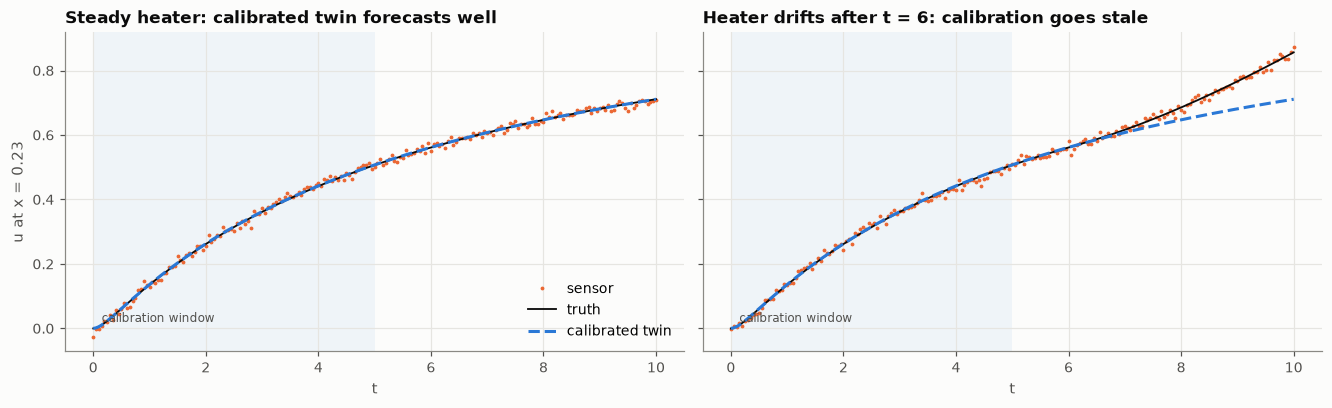

In [8]:
half = t <= 5
def res_half(th):
    _, (_, U) = forward(*th)
    return ((sens.observe(U)[half] - Y[half]) / SIGMA).ravel()

f_half = least_squares(res_half, [0.008, 0.5], x_scale=[0.01, 0.5], diff_step=1e-4)
_, (_, U_cal) = forward(*f_half.x)

drift = lambda tt: P_TRUE * (1 + 0.6 * np.clip(tt - 6, 0, None) / 4)
m = Heat1D(nx=NX, alpha=ALPHA_TRUE, dt=DT)
_, U_drift = m.simulate(np.zeros(NX), NSTEP, source=lambda x, tt: drift(tt) * shape(x))
Y_drift = sens.observe(U_drift, rng)

j = 1
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), constrained_layout=True, sharey=True)
for ax, Yd, Ud, ttl in [(axes[0], Y, U_true, "Steady heater: calibrated twin forecasts well"),
                        (axes[1], Y_drift, U_drift, "Heater drifts after t = 6: calibration goes stale")]:
    ax.axvspan(0, 5, color=viz.BLUE, alpha=0.06, lw=0)
    ax.text(0.15, 0.02, "calibration window", color=viz.INK2, fontsize=8)
    ax.plot(t, Yd[:, j], ".", color=viz.DATA, ms=3, label="sensor")
    ax.plot(t, Ud[:, sens.idx[j]], color=viz.TRUTH, lw=1.2, label="truth")
    ax.plot(t, U_cal[:, sens.idx[j]], color=viz.TWIN, ls="--", label="calibrated twin")
    ax.set(xlabel="t", title=ttl)
axes[0].set_ylabel(f"u at x = {x[sens.idx[j]]:.2f}")
axes[0].legend()
plt.show()

## Part A summary
* Calibration = nonlinear least squares, which is maximum likelihood under Gaussian noise.
* Gauss-Newton linearises and solves the normal equations $J^\top J\,\delta = -J^\top r$.
* **Look at the landscape.** Valleys mean correlated parameters; flat directions mean the data
  can't see them (identifiability).
* $(J^\top J)^{-1}$ gives cheap error bars; Monte Carlo confirms them.
* **Where you put the sensors** matters as much as the algorithm.
* Offline calibration assumes constant parameters. When the asset changes, the twin must keep
  learning while it runs. That is Part B.

---
# Part B · The Kalman filter: a twin that learns while it runs

## B1. The core idea with a single number
Forget fields for a moment. You want the temperature $u$ of one spot.
* Your **model** forecasts $u^f = 20.0$°C, and you trust it to about $\pm\sqrt{P} = 1.0$°C.
* A **sensor** reads $y = 22.0$°C, with noise $\pm\sqrt{R} = 0.5$°C.

What is your best guess? Neither number alone. Take a **weighted average** that gives more weight
to whichever source is more precise:

$$u^a = u^f + K\,(y - u^f), \qquad K = \frac{P}{P + R}, \qquad P^a = (1 - K)\,P$$

* $y - u^f$ is the **innovation**, the surprise.
* $K \in [0, 1]$ is the **Kalman gain**. With a perfect sensor ($R = 0$) $K = 1$: trust the
  data. With a perfect model ($P = 0$) $K = 0$: ignore the data.
* The new uncertainty $P^a$ is **smaller than both** $P$ and $R$. Combining information always
  helps.

This is Bayes' rule for two Gaussians. In numbers:

gain K = 0.80;  analysis = 20.0 + 0.80 * (22.0 - 20.0) = 21.60
std: model 1.00, sensor 0.50  ->  combined 0.45


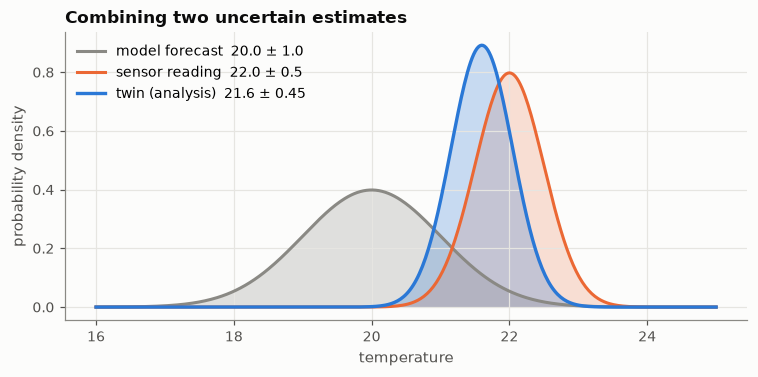

In [9]:
uf, Pf, y0, R0 = 20.0, 1.0**2, 22.0, 0.5**2
K0 = Pf / (Pf + R0)
ua, Pa = uf + K0 * (y0 - uf), (1 - K0) * Pf
print(f"gain K = {K0:.2f};  analysis = {uf} + {K0:.2f} * ({y0} - {uf}) = {ua:.2f}")
print(f"std: model {np.sqrt(Pf):.2f}, sensor {np.sqrt(R0):.2f}  ->  combined {np.sqrt(Pa):.2f}")

g = np.linspace(16, 25, 400)
gauss = lambda m, v: np.exp(-(g - m) ** 2 / (2 * v)) / np.sqrt(2 * np.pi * v)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.fill_between(g, gauss(uf, Pf), color=viz.MUTED, alpha=0.25, lw=0)
ax.plot(g, gauss(uf, Pf), color=viz.MUTED, label=f"model forecast  {uf} ± {np.sqrt(Pf):.1f}")
ax.fill_between(g, gauss(y0, R0), color=viz.DATA, alpha=0.2, lw=0)
ax.plot(g, gauss(y0, R0), color=viz.DATA, label=f"sensor reading  {y0} ± {np.sqrt(R0):.1f}")
ax.fill_between(g, gauss(ua, Pa), color=viz.TWIN, alpha=0.25, lw=0)
ax.plot(g, gauss(ua, Pa), color=viz.TWIN, lw=2.2, label=f"twin (analysis)  {ua:.1f} ± {np.sqrt(Pa):.2f}")
ax.set(xlabel="temperature", ylabel="probability density", title="Combining two uncertain estimates")
ax.legend()
plt.show()

If the sensor were as noisy as the model ($R = P$), the gain would be $K = 0.5$ and the analysis
the plain average, 21.0; the uncertainty would drop by a factor $\sqrt2$.

## B2. The same idea over time: forecast, then correct
A twin repeats two steps forever:
1. **Forecast:** run the model one step. Uncertainty **grows**: $P \leftarrow a^2P + Q$, where
   $Q$ is the model error per step.
2. **Analysis:** a reading arrives, so blend it in as above. Uncertainty **shrinks**.

Below, one temperature drifts slowly as a random walk (the model knows only "it stays about the
same", so $a = 1$). Watch the gain settle: the filter finds its own balance between model and data.

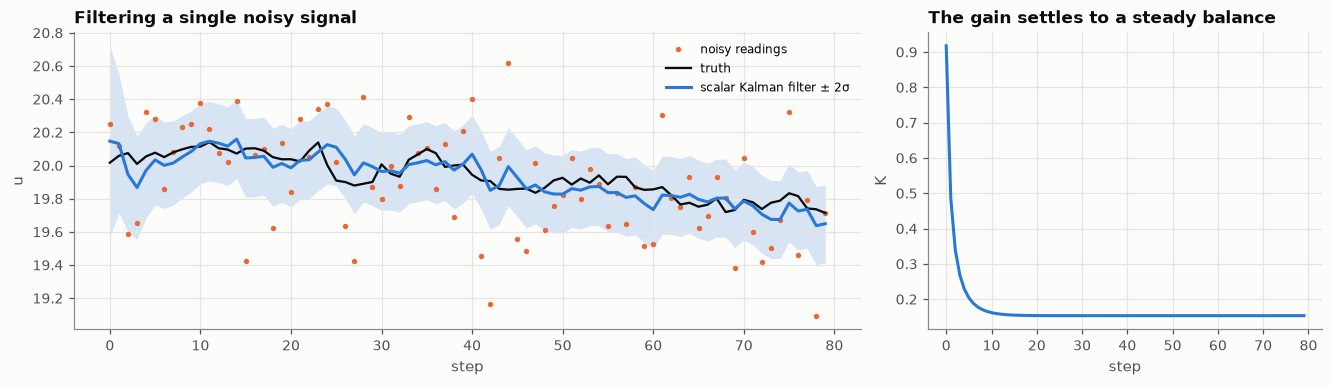

RMSE: raw readings 0.283, filter 0.073


In [10]:
rs = np.random.default_rng(1)
nT, Q1, R1 = 80, 0.05**2, 0.3**2
truth1 = np.cumsum(rs.normal(0, 0.05, nT)) + 20
y1 = truth1 + rs.normal(0, np.sqrt(R1), nT)
u, P = 19.0, 1.0
est, sd1, gains = [], [], []
for k in range(nT):
    P = P + Q1                         # forecast: model error adds uncertainty
    K = P / (P + R1)                   # gain
    u = u + K * (y1[k] - u)            # analysis
    P = (1 - K) * P
    est.append(u); sd1.append(np.sqrt(P)); gains.append(K)
est, sd1 = np.array(est), np.array(sd1)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), constrained_layout=True,
                         gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
ax.plot(y1, ".", color=viz.DATA, ms=5, label="noisy readings")
ax.plot(truth1, color=viz.TRUTH, lw=1.5, label="truth")
viz.band(ax, np.arange(nT), est, sd1, color=viz.TWIN, label="scalar Kalman filter ± 2σ")
ax.set(xlabel="step", ylabel="u", title="Filtering a single noisy signal")
ax.legend(fontsize=8)
axes[1].plot(gains, color=viz.TWIN)
axes[1].set(xlabel="step", ylabel="K", title="The gain settles to a steady balance")
plt.show()
print(f"RMSE: raw readings {np.sqrt(np.mean((y1-truth1)**2)):.3f}, filter {np.sqrt(np.mean((est-truth1)**2)):.3f}")

The filter's error is several times smaller than the raw readings', because it
averages over time in an optimal way.

## B3. From one number to a whole field
Replace every scalar by its matrix version:

| Scalar | Field (vector/matrix) | Meaning |
|---|---|---|
| $u$ | $\mathbf x$ (all 81 temperatures, and later the heater power) | state |
| $a$ | $M$ from `Heat1D.transition_matrices()` | one model step |
| $P$ | $P$ ($n \times n$ covariance) | uncertainty, **and how errors at different points are related** |
| $y - u$ | $\mathbf y - H\mathbf x$ | innovation at each sensor |
| $K = P/(P+R)$ | $K = PH^\top(HPH^\top + R)^{-1}$ | gain, one column per sensor |

| Step | Equation |
|---|---|
| **Forecast** | $\mathbf x^f_k = M\mathbf x^a_{k-1}$, $\quad P^f_k = M P^a_{k-1}M^\top + Q$ |
| **Analysis** | $\mathbf x^a_k = \mathbf x^f_k + K(\mathbf y_k - H\mathbf x^f_k)$, $\quad P^a_k = (I - KH)P^f_k$ |

The off-diagonal entries of $P$ do the work. They say "if the twin is too cold at the sensor,
it is probably too cold next to it as well". That's how one sensor corrects **the whole
neighbourhood**, including points with no sensor. The KF is *optimal* for linear models with
Gaussian noise, and the heat equation is linear.

**The scenario.** The heater power $q(t)$ is unknown and changes over time (an operator turns a
knob). We estimate the full temperature field **and** $q(t)$ live from 5 thermometers, none of
them on the heater. The trick is called **state augmentation**: put the unknown input into the
state vector and let the filter estimate it like any other state.

In [11]:
rng = np.random.default_rng(7)

## B4. Reality: an operator-controlled heater plus small unmodelled disturbances

In [12]:
NX, DT, NSTEP, ALPHA = 81, 0.05, 400, 0.012
rod = Heat1D(nx=NX, alpha=ALPHA, dt=DT)
x = rod.x
b = np.exp(-((x - 0.35) / 0.05) ** 2)        # heater footprint (known)

def q_true(t):                               # heater power (unknown to the twin)
    return np.select([t < 4, t < 9, t < 14], [0.5, 1.2, 1.2 - 0.12 * (t - 9)], 0.3)

t = np.arange(NSTEP + 1) * DT
U_true = np.zeros((NSTEP + 1, NX))
for k in range(NSTEP):
    disturbance = gaussian_filter1d(rng.standard_normal(NX), 3) * 0.004 * rod.mask
    U_true[k + 1] = rod.step(U_true[k], q_true(t[k]) * b) + disturbance

sens = PointSensors(evenly_spaced_1d(NX, 5), NX, noise_std=0.01)
Y = sens.observe(U_true, rng)
xs = x[sens.idx]

## B5. Building the filter: augmented linear model
Write the state as $z = [u;\, q]$. The heater power has no dynamics of its own, so we model it as
a **random walk** $q_{k+1} = q_k + \eta_k$: "it stays the same unless the data say otherwise."

$$\begin{bmatrix}u\\q\end{bmatrix}_{k+1} = \underbrace{\begin{bmatrix}M & G b\\ 0 & 1\end{bmatrix}}_{M_{\text{aug}}}\begin{bmatrix}u\\q\end{bmatrix}_k + w_k,\qquad Q = \operatorname{diag}(\sigma_u^2 I,\ \sigma_q^2)$$

The size of $\sigma_q$ encodes how fast we believe the knob can move. It is the main tuning knob.

In [13]:
M, G = rod.transition_matrices()
n = NX + 1
M_aug = np.zeros((n, n))
M_aug[:NX, :NX] = M
M_aug[:NX, NX] = G @ b
M_aug[NX, NX] = 1.0
H_aug = np.hstack([sens.H, np.zeros((sens.m, 1))])

def run_kf(sigma_q=0.03, sigma_u=0.004, q0=0.3):
    Q = np.diag(np.r_[np.full(NX, sigma_u**2) * rod.mask + 1e-12, sigma_q**2])
    kf = KalmanFilter(M_aug, H_aug, Q, sens.R)
    z = np.r_[np.zeros(NX), q0]
    P = np.diag(np.r_[np.full(NX, 1e-4), 0.5**2])
    Z, S_diag, nis = [z], [np.sqrt(np.diag(P))], [np.nan]
    for k in range(1, NSTEP + 1):
        z, P = kf.predict(z, P)
        z, P, innov, S = kf.update(z, P, Y[k])
        Z.append(z)
        S_diag.append(np.sqrt(np.diag(P)))
        nis.append(innov @ np.linalg.solve(S, innov))
    return np.array(Z), np.array(S_diag), np.array(nis), P

Z, SD, NIS, P_final = run_kf()
U_kf, q_kf, U_sd, q_sd = Z[:, :NX], Z[:, NX], SD[:, :NX], SD[:, NX]

# open-loop twin for comparison: assumes a constant heater power of 0.6
U_open = np.zeros_like(U_true)
for k in range(NSTEP):
    U_open[k + 1] = rod.step(U_open[k], 0.6 * b)

## B6. The twin sees the whole field

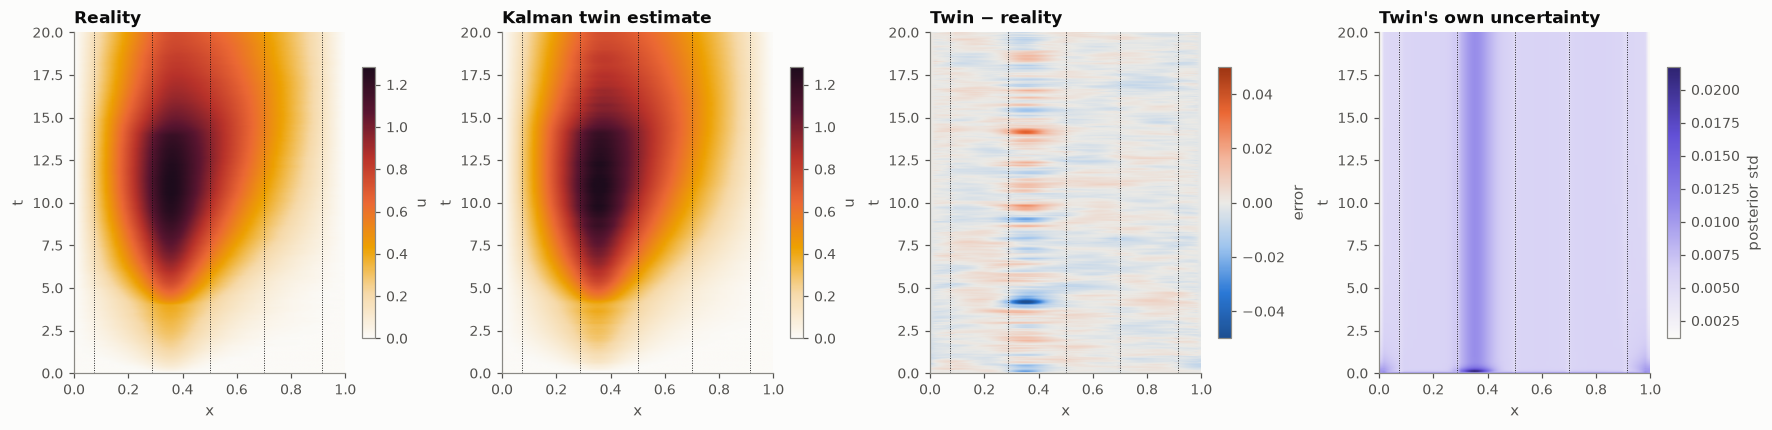

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), constrained_layout=True)
vmax = U_true.max()
viz.spacetime(axes[0], U_true, x, t, vmin=0, vmax=vmax, label="u")
axes[0].set_title("Reality")
viz.spacetime(axes[1], U_kf, x, t, vmin=0, vmax=vmax, label="u")
axes[1].set_title("Kalman twin estimate")
err = U_kf - U_true
viz.spacetime(axes[2], err, x, t, cmap=viz.DIVERGING, vmin=-0.05, vmax=0.05, label="error")
axes[2].set_title("Twin − reality")
viz.spacetime(axes[3], U_sd, x, t, cmap=viz.UNCERTAINTY, label="posterior std")
axes[3].set_title("Twin's own uncertainty")
for ax in axes:
    for xi in xs:
        ax.axvline(xi, color=viz.INK, lw=0.6, ls=":")
viz.save(fig, "04_kalman_field.png")
plt.show()

Note the stripes in the uncertainty map: the std collapses at the sensors (dotted lines) and
stays largest midway between them and around the heater. **A good twin knows where it is unsure.**

## B7. Estimating something no sensor measures: the heater power

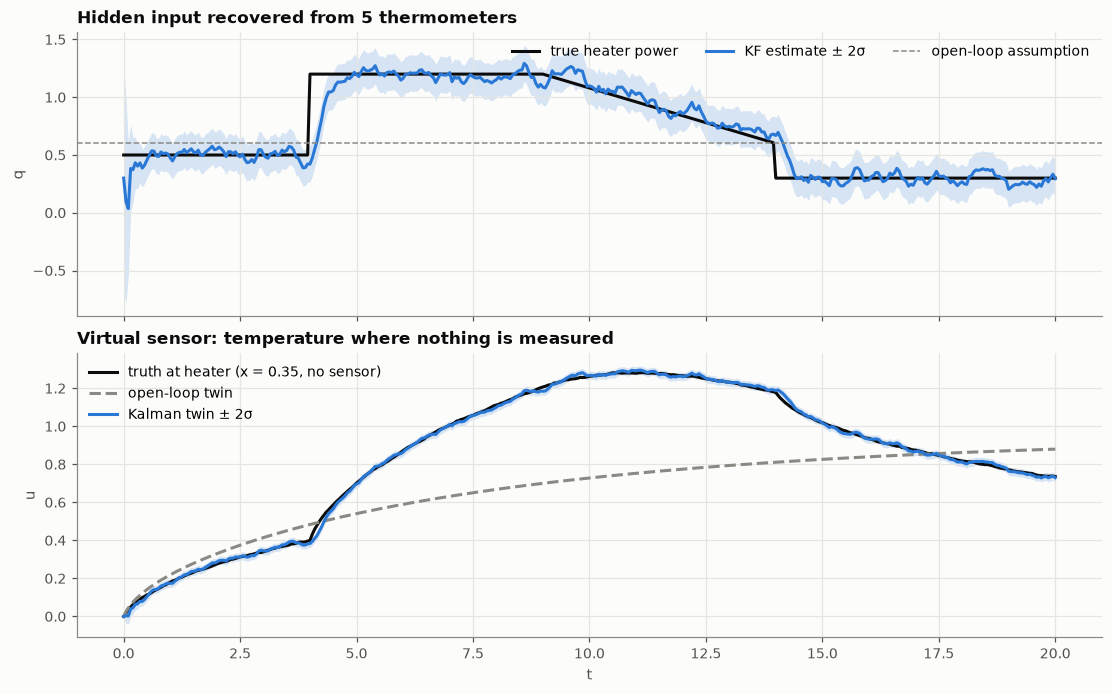

In [15]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6.2), constrained_layout=True, sharex=True)
ax = axes[0]
ax.plot(t, q_true(t), color=viz.TRUTH, lw=2, label="true heater power")
viz.band(ax, t, q_kf, q_sd, color=viz.TWIN, label="KF estimate ± 2σ")
ax.axhline(0.6, color=viz.MUTED, ls="--", lw=1, label="open-loop assumption")
ax.set(ylabel="q", title="Hidden input recovered from 5 thermometers")
ax.legend(ncol=3, loc="upper right")

ax = axes[1]
ih = np.argmin(abs(x - 0.35))
ax.plot(t, U_true[:, ih], color=viz.TRUTH, lw=2, label="truth at heater (x = 0.35, no sensor)")
ax.plot(t, U_open[:, ih], color=viz.MUTED, ls="--", label="open-loop twin")
viz.band(ax, t, U_kf[:, ih], U_sd[:, ih], color=viz.TWIN, label="Kalman twin ± 2σ")
ax.set(xlabel="t", ylabel="u", title="Virtual sensor: temperature where nothing is measured")
ax.legend(loc="upper left")
plt.show()

The estimate lags the true power by a fraction of a time unit: heat needs time to diffuse to the
sensors, so no filter can react instantly. This lag is a physical limit, not a bug.

## B8. Accuracy over time

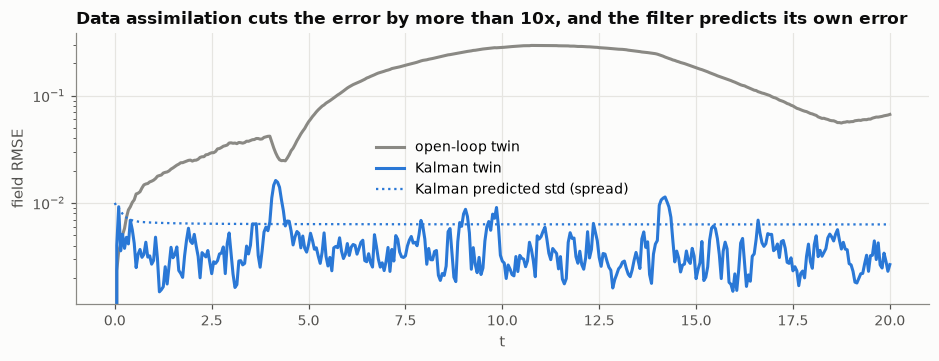

In [16]:
rmse = lambda A: np.sqrt(((A - U_true) ** 2).mean(1))
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t, rmse(U_open), color=viz.MUTED, label="open-loop twin")
ax.plot(t, rmse(U_kf), color=viz.TWIN, label="Kalman twin")
ax.plot(t, np.sqrt((U_sd**2).mean(1)), color=viz.TWIN, ls=":", lw=1.5, label="Kalman predicted std (spread)")
ax.set(xlabel="t", ylabel="field RMSE", yscale="log", title="Data assimilation cuts the error by more than 10x, and the filter predicts its own error")
ax.legend()
plt.show()

## B9. What the covariance knows
The final $P$ matrix as a correlation map. Rows/columns 0-80 are rod positions, the last one is the
heater power. Bright off-diagonal bands mean "learning about one point tells you about the
other". The heater row shows *where on the rod* temperature errors are correlated with errors in $q$.

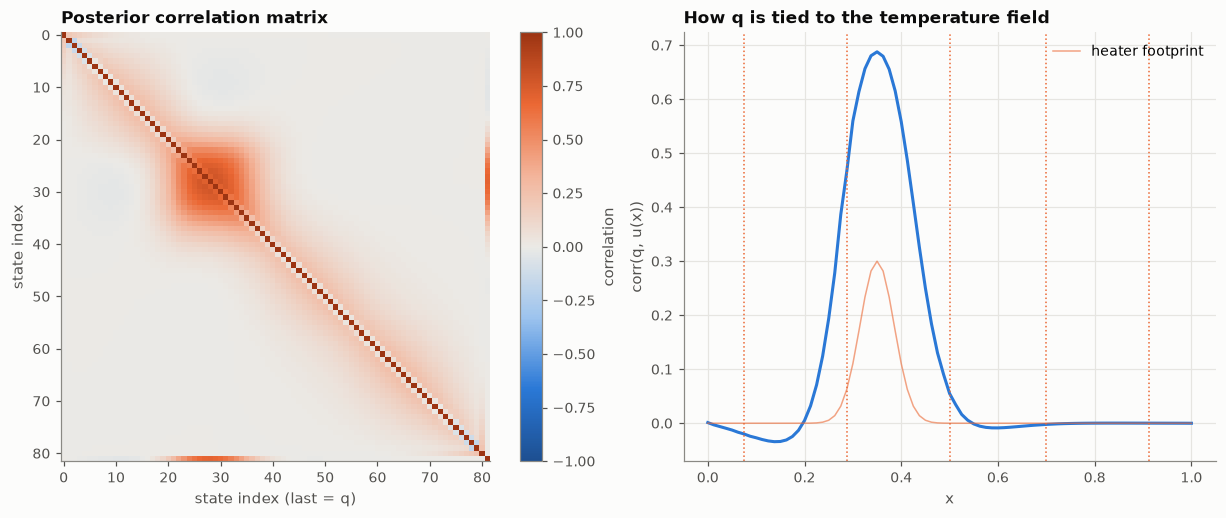

In [17]:
sd = np.sqrt(np.diag(P_final))
Corr = P_final / np.outer(sd, sd)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), constrained_layout=True,
                         gridspec_kw={"width_ratios": [1.1, 1]})
axes[0].grid(False)
im = axes[0].imshow(Corr, cmap=viz.DIVERGING, vmin=-1, vmax=1, interpolation="nearest")
plt.colorbar(im, ax=axes[0], label="correlation")
axes[0].set(title="Posterior correlation matrix", xlabel="state index (last = q)", ylabel="state index")
axes[1].plot(x, Corr[NX, :NX], color=viz.TWIN)
for xi in xs:
    axes[1].axvline(xi, color=viz.DATA, lw=1, ls=":")
axes[1].plot(x, 0.3 * b, color=viz.ORANGE, lw=1, alpha=0.6, label="heater footprint")
axes[1].set(xlabel="x", ylabel="corr(q, u(x))", title="How q is tied to the temperature field")
axes[1].legend()
plt.show()

## B10. Is the filter honest? Consistency check
If the model and noise assumptions are right, the **normalised innovation squared**
$\mathrm{NIS}_k = d_k^\top S_k^{-1} d_k$ follows a $\chi^2_m$ distribution ($m=5$ sensors). Too
high means the filter is over-confident (Q too small); too low means it's too timid. This is also
the basis of **anomaly detection** in the capstone (Chapter 6).

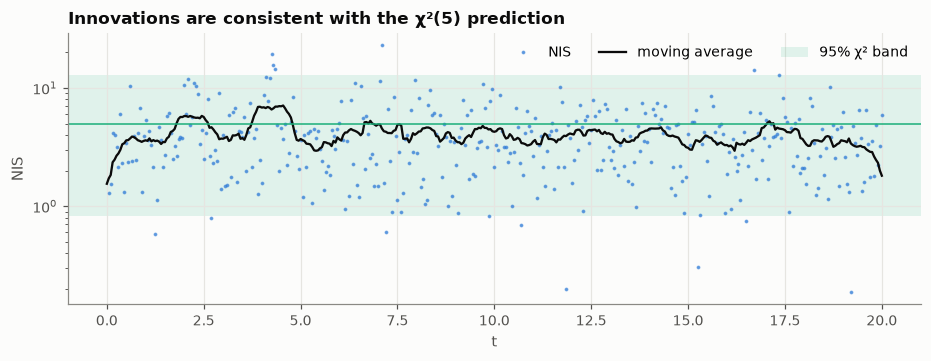

In [18]:
lo, hi = chi2.ppf([0.025, 0.975], sens.m)
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(t, NIS, ".", color=viz.TWIN, ms=3, alpha=0.6, label="NIS")
ax.plot(t, np.convolve(np.nan_to_num(NIS, nan=sens.m), np.ones(20) / 20, mode="same"), color=viz.INK, lw=1.5, label="moving average")
ax.axhspan(lo, hi, color=viz.AQUA, alpha=0.12, lw=0, label="95% χ² band")
ax.axhline(sens.m, color=viz.AQUA, lw=1)
ax.set(xlabel="t", ylabel="NIS", yscale="log", title="Innovations are consistent with the χ²(5) prediction")
ax.legend(ncol=3)
plt.show()

## B11. Tuning: the process noise trade-off
$\sigma_q$ says how fast the twin *believes* the heater can change.

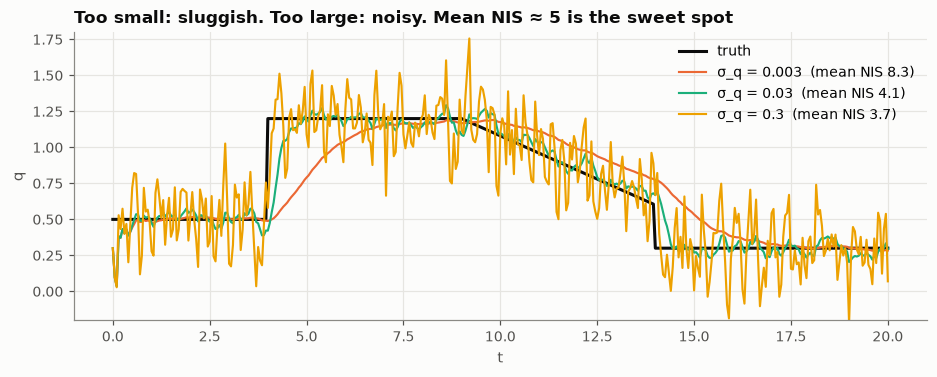

In [19]:
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t, q_true(t), color=viz.TRUTH, lw=2, label="truth")
for i, sq in enumerate([0.003, 0.03, 0.3]):
    Zs, _, nis_s, _ = run_kf(sigma_q=sq)
    ax.plot(t, Zs[:, NX], color=viz.SERIES[i + 1], lw=1.4,
            label=f"σ_q = {sq}  (mean NIS {np.nanmean(nis_s):.1f})")
ax.set(xlabel="t", ylabel="q", ylim=(-0.2, 1.8), title="Too small: sluggish. Too large: noisy. Mean NIS ≈ 5 is the sweet spot")
ax.legend(loc="upper right")
plt.show()

## B12. Watch the twin track reality

In [20]:
idx = np.arange(0, NSTEP + 1, 6)
fig_anim = viz.animate_1d(x, [U_true[idx], U_kf[idx], U_open[idx]], t[idx],
                          labels=["reality", "Kalman twin", "open-loop twin"],
                          colors=[viz.TRUTH, viz.TWIN, viz.MUTED], styles=["-", "-", "--"],
                          points=(xs, Y[idx]), title="Live twin")
HTML(fig_anim.to_jshtml())

---
# Summary
| | Calibration (Part A) | Kalman filter (Part B) |
|---|---|---|
| runs | offline, once | online, every step |
| estimates | constant parameters | changing states and inputs (parameters too, via augmentation) |
| uncertainty | $(J^\top J)^{-1}$ | the covariance $P$, updated every step |
| main risk | stale when the asset changes | over-confidence if $Q$ is too small (watch NIS) |

**Key ideas**
1. Least squares = maximum likelihood with Gaussian noise.
2. Correlated parameters form valleys in the loss; sensor placement decides what is identifiable.
3. The Kalman gain is a precision-weighted average: $K = P/(P+R)$ in 1D.
4. The covariance spreads a sensor's correction to unsensed points and to hidden inputs.
5. NIS ≈ number of sensors means the filter is honest; persistent large NIS means something is
   wrong. That is an **alarm**.

**Limits:** the KF stores the full $n \times n$ covariance ($O(n^2)$ memory, $O(n^3)$ time) and
needs a linear model. A 2D field has thousands of cells and parameters that enter nonlinearly,
so Chapter 3 introduces the **ensemble Kalman filter**.
